In [205]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler,MinMaxScaler,LabelEncoder

In [206]:
df=pd.read_csv("Employee.csv")
df.head()

,Company,Age,Salary,Place,Country,Gender
0,TCS,20.0,NaN,Chennai,India,0
1,Infosys,30.0,NaN,Mumbai,India,0
2,TCS,35.0,2300.0,Calcutta,India,0
3,Infosys,40.0,3000.0,Delhi,India,0
4,TCS,23.0,4000.0,Mumbai,India,0


#1

In [207]:
df.shape

(148, 6)

In [208]:
df.describe()

,Age,Salary,Gender
count,130.000000,124.000000,148.000000
mean,30.484615,5312.467742,0.222973
std,11.096640,2573.764683,0.417654
min,0.000000,1089.000000,0.000000
25%,22.000000,3030.000000,0.000000
50%,32.500000,5000.000000,0.000000
75%,37.750000,8000.000000,0.000000
max,54.000000,9876.000000,1.000000


In [209]:
df['Company'].unique()

<ArrowStringArray>
[                      'TCS',                   'Infosys',
                       'CTS',                         nan,
 'Tata Consultancy Services',                'Congnizant',
           'Infosys Pvt Lmt']
Length: 7, dtype: str

In [210]:
df['Place'].unique()

<ArrowStringArray>
[   'Chennai',     'Mumbai',   'Calcutta',      'Delhi', 'Podicherry',
     'Cochin',          nan,      'Noida',  'Hyderabad',     'Bhopal',
     'Nagpur',       'Pune']
Length: 12, dtype: str

In [211]:
df['Country'].unique()

<ArrowStringArray>
['India']
Length: 1, dtype: str

In [212]:
df['Gender'].unique()

array([0, 1])

In [213]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Company  140 non-null    str    
 1   Age      130 non-null    float64
 2   Salary   124 non-null    float64
 3   Place    134 non-null    str    
 4   Country  148 non-null    str    
 5   Gender   148 non-null    int64  
dtypes: float64(2), int64(1), str(3)
memory usage: 9.4 KB


In [214]:
df.isna().mean()*100

Company     5.405405
Age        12.162162
Salary     16.216216
Place       9.459459
Country     0.000000
Gender      0.000000
dtype: float64

#2

In [215]:
df.duplicated().sum()     #treating duplicates

np.int64(4)

In [216]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [217]:
mean = df['Salary'].mean()     #treating null
df['Salary']=df['Salary'].fillna(mean,inplace=True)

In [218]:
df['Age'] = df['Age'].replace(0, np.nan)   #replacing NaN for 0
df['Age'].isna().sum()

np.int64(23)

In [219]:
df['Age']=df['Age'].fillna(df['Age'].mean())

In [220]:
df['Company'].mode()

0    TCS
Name: Company, dtype: str

In [221]:
df['Company']=df['Company'].fillna('TCS',inplace=True)

In [222]:
df['Place'].mode()

0    Mumbai
Name: Place, dtype: str

In [223]:
df['Place']=df['Place'].fillna('Mumbai',inplace=True)

In [224]:
df.isnull().sum()

Company    0
Age        0
Salary     0
Place      0
Country    0
Gender     0
dtype: int64

In [225]:
outlier_cols = df.select_dtypes(include=np.number)  #finding ouliers
outlier_cols.columns

Index(['Age', 'Salary', 'Gender'], dtype='str')

<Axes: xlabel='Age'>

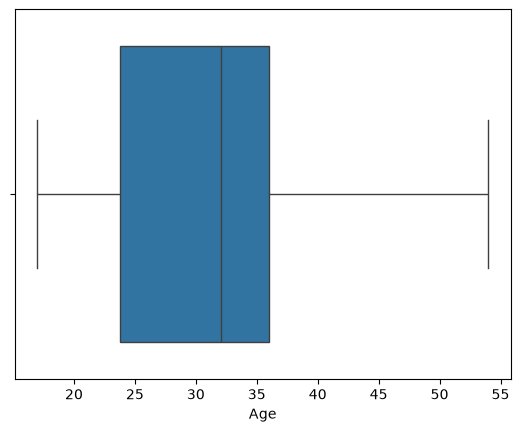

In [226]:
sns.boxplot(x=df['Age'],data=df)

<Axes: xlabel='Salary'>

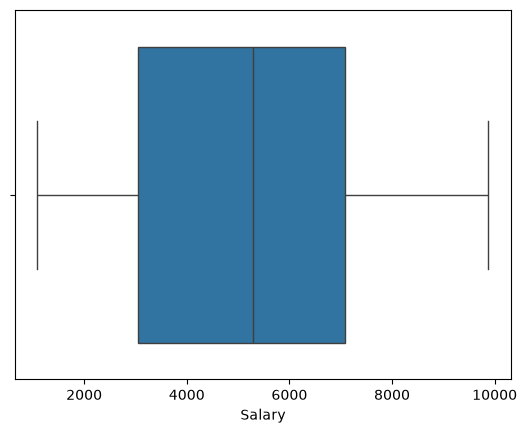

In [227]:
sns.boxplot(x=df['Salary'],data=df)

In [228]:
#No outliers found from the plots

#3

Text(0.5, 1.0, 'Scatter plot of filtered data')

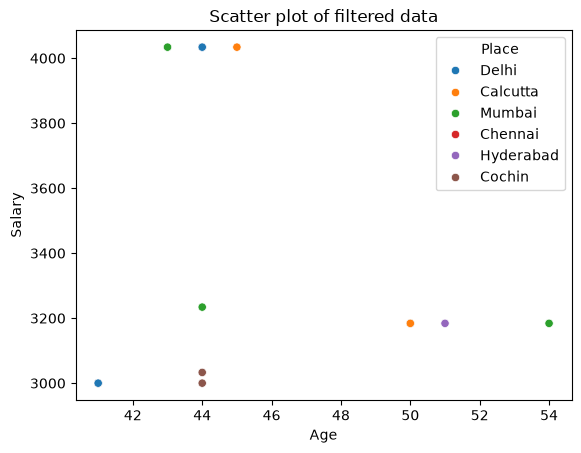

In [229]:
filtered=df[(df['Age']>40)&(df['Salary']<5000)]
sns.scatterplot(data=filtered,x='Age',y='Salary',hue='Place')
plt.title('Scatter plot of filtered data')

Text(0.5, 1.0, 'Scatter plot of age vs salary')

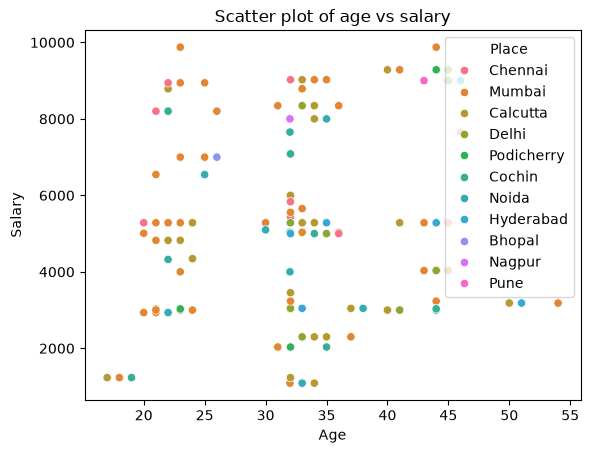

In [230]:
sns.scatterplot(data=df,x='Age',y='Salary',hue='Place')
plt.title('Scatter plot of age vs salary')

Text(0, 0.5, 'Count')

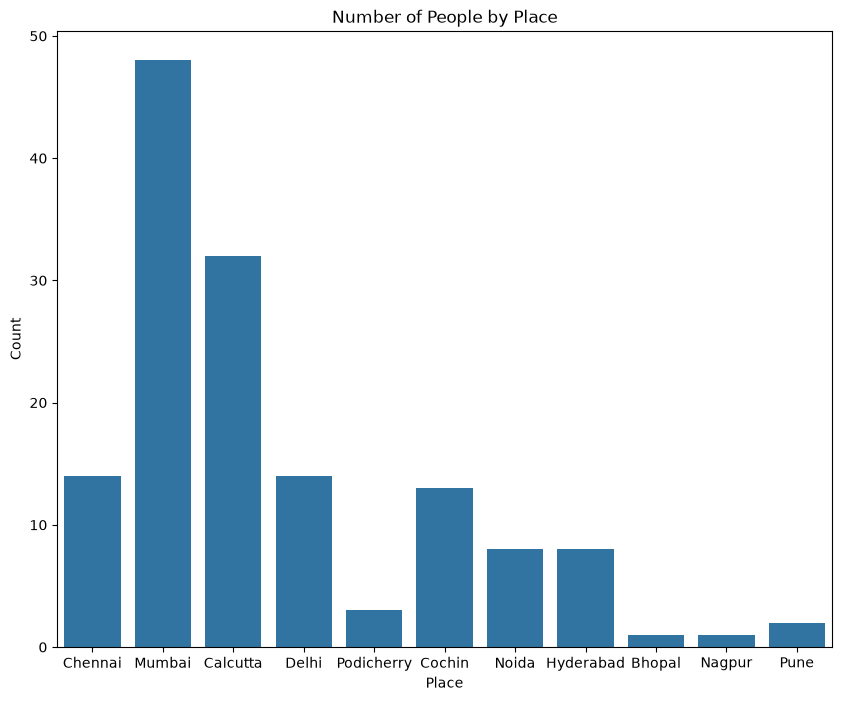

In [231]:
plt.figure(figsize=(10,8))
sns.countplot(data=df,x='Place')
plt.title('Number of People by Place')
plt.xlabel('Place')
plt.ylabel('Count')

#4

In [232]:
df.drop(columns=['Country'], inplace=True)
df.head()

,Company,Age,Salary,Place,Gender
0,TCS,20.0,5283.471074,Chennai,0
1,Infosys,30.0,5283.471074,Mumbai,0
2,TCS,35.0,2300.000000,Calcutta,0
3,Infosys,40.0,3000.000000,Delhi,0
4,TCS,23.0,4000.000000,Mumbai,0


In [233]:
le=LabelEncoder()
df["Place"]= le.fit_transform(df["Place"])
df["Place"].unique()

array([ 2,  6,  1,  4,  9,  3,  8,  5,  0,  7, 10])

In [234]:
df['Company'].unique()

<ArrowStringArray>
[                      'TCS',                   'Infosys',
                       'CTS', 'Tata Consultancy Services',
                'Congnizant',           'Infosys Pvt Lmt']
Length: 6, dtype: str

In [235]:
df['Company']=df['Company'].map({'TCS':1,'Tata Consultancy Services':1,'CTS':2,'Congnizant':2,'Infosys':3,'Infosys Pvt Lmt':3})
df['Company'].unique()

array([1, 3, 2])

#5

<Axes: >

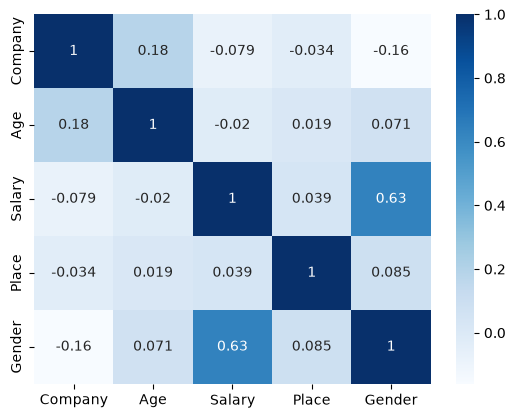

In [236]:
sns.heatmap(df.corr(),annot=True,cmap='Blues')

In [237]:
x=df.drop("Salary",axis=1)
y=df["Salary"]

In [238]:
std=StandardScaler()
x_std=std.fit_transform(x)
x_std

array([[-1.03286173, -1.46737581, -0.89325451, -0.53452248],
       [ 1.3093759 , -0.24875897,  0.7505621 , -0.53452248],
       [-1.03286173,  0.36054944, -1.30420866, -0.53452248],
       [ 1.3093759 ,  0.96985786, -0.07134621, -0.53452248],
       [-1.03286173, -1.10179076,  0.7505621 , -0.53452248],
       [ 1.3093759 ,  0.        , -1.30420866, -0.53452248],
       [-1.03286173,  0.        , -0.89325451,  1.87082869],
       [ 1.3093759 , -1.10179076,  0.7505621 ,  1.87082869],
       [-1.03286173,  0.23868776, -1.30420866,  1.87082869],
       [ 0.13825708,  1.57916628, -0.07134621, -0.53452248],
       [ 0.13825708, -1.10179076,  0.7505621 , -0.53452248],
       [ 0.13825708,  0.23868776, -1.30420866, -0.53452248],
       [ 0.13825708,  1.57916628, -0.89325451, -0.53452248],
       [ 0.13825708, -1.71109918,  0.7505621 , -0.53452248],
       [ 1.3093759 ,  0.96985786, -1.30420866, -0.53452248],
       [-1.03286173, -1.10179076, -0.07134621, -0.53452248],
       [ 1.3093759 , -1.

In [239]:
x_std=pd.DataFrame(x_std)
x_std.describe()

,0,1,2,3
count,1.440000e+02,1.440000e+02,1.440000e+02,1.440000e+02
mean,5.396917e-17,-4.780127e-17,1.804112e-16,6.167906e-17
std,1.003490e+00,1.003490e+00,1.003490e+00,1.003490e+00
min,-1.032862e+00,-1.832961e+00,-1.715163e+00,-5.345225e-01
25%,-1.032862e+00,-1.010394e+00,-8.932545e-01,-5.345225e-01
50%,1.382571e-01,0.000000e+00,-7.134621e-02,-5.345225e-01
75%,1.309376e+00,4.824111e-01,7.505621e-01,-5.345225e-01
max,1.309376e+00,2.675921e+00,2.394379e+00,1.870829e+00


In [240]:
scaler=MinMaxScaler()
x_min=scaler.fit_transform(x)
x_min

array([[0.        , 0.08108108, 0.2       , 0.        ],
       [1.        , 0.35135135, 0.6       , 0.        ],
       [0.        , 0.48648649, 0.1       , 0.        ],
       [1.        , 0.62162162, 0.4       , 0.        ],
       [0.        , 0.16216216, 0.6       , 0.        ],
       [1.        , 0.40652222, 0.1       , 0.        ],
       [0.        , 0.40652222, 0.2       , 1.        ],
       [1.        , 0.16216216, 0.6       , 1.        ],
       [0.        , 0.45945946, 0.1       , 1.        ],
       [0.5       , 0.75675676, 0.4       , 0.        ],
       [0.5       , 0.16216216, 0.6       , 0.        ],
       [0.5       , 0.45945946, 0.1       , 0.        ],
       [0.5       , 0.75675676, 0.2       , 0.        ],
       [0.5       , 0.02702703, 0.6       , 0.        ],
       [1.        , 0.62162162, 0.1       , 0.        ],
       [0.        , 0.16216216, 0.4       , 0.        ],
       [1.        , 0.16216216, 0.9       , 0.        ],
       [0.        , 0.45945946,

In [241]:
x_min=pd.DataFrame(x_min)
x_min.describe()

,0,1,2,3
count,144.000000,144.000000,144.000000,144.000000
mean,0.440972,0.406522,0.417361,0.222222
std,0.428432,0.222559,0.244185,0.417191
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.182432,0.200000,0.000000
50%,0.500000,0.406522,0.400000,0.000000
75%,1.000000,0.513514,0.600000,0.000000
max,1.000000,1.000000,1.000000,1.000000
